# Jobsheet 07 - Lab 1: K-Means Clustering pada Dataset Iris
**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Institusi:** Jurusan Teknologi Informasi - Politeknik Negeri Malang  
**Topik:** Pengenalan Model K-Means, Scatterplot Visual, Evaluasi SSE (Inertia), dan Penentuan $k$ Terbaik Menggunakan Elbow Method


## Langkah 1 - Import Library
Pada langkah ini, kita mengimpor pustaka utama yang dibutuhkan untuk manipulasi data (`pandas`, `numpy`), visualisasi data (`matplotlib.pyplot`, `seaborn`), dan algoritma klasterisasi K-Means dari `sklearn.cluster`.


In [1]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import os
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## Langkah 2 - Load dan Inspeksi Data
Pada tahap ini, dataset bunga Iris dimuat ke dalam DataFrame Pandas. Kita menampilkan 5 baris pertama serta informasi struktur dataset (`df.info()`).


In [2]:
# Muat data dari folder Dataset atau direktori saat ini
data_path = 'Dataset/iris.csv' if os.path.exists('Dataset/iris.csv') else 'iris.csv'
df = pd.read_csv(data_path)
df.head()


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Cek ringkasan profil data dan keberadaan missing value
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


Berdasarkan inspeksi data:
- Terdapat 150 sampel data bunga Iris dengan 6 variabel.
- Tidak terdapat nilai yang hilang (*missing values*) pada seluruh kolom.
- Kolom `Id` bertindak sebagai identifier dan `Species` bertindak sebagai label target asli (ground truth).


## Langkah 3 - Seleksi Fitur
Karena klasterisasi merupakan metode *unsupervised learning*, kita mengasumsikan data tidak memiliki label. Oleh karena itu, kita memisahkan fitur prediktor dari identifier `Id` dan label `Species` menggunakan teknik slicing `iloc[:, 1:-1]`.


In [4]:
# Seleksi fitur: mengambil kolom index ke-1 hingga sebelum terakhir
X = df.iloc[:, 1:-1] # Fitur numerik (SepalLength, SepalWidth, PetalLength, PetalWidth)
y = df.iloc[:, -1]   # Label spesies (hanya untuk referensi/evaluasi pembanding)

print("5 Baris Pertama Matriks Fitur X:")
print(X.head())


5 Baris Pertama Matriks Fitur X:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


## Langkah 4 - Plotting Scatter Plot Awal
Visualisasi awal sebaran data menggunakan scatter plot pada dua fitur pertama, yaitu `SepalLengthCm` (sumbu X) dan `SepalWidthCm` (sumbu Y).


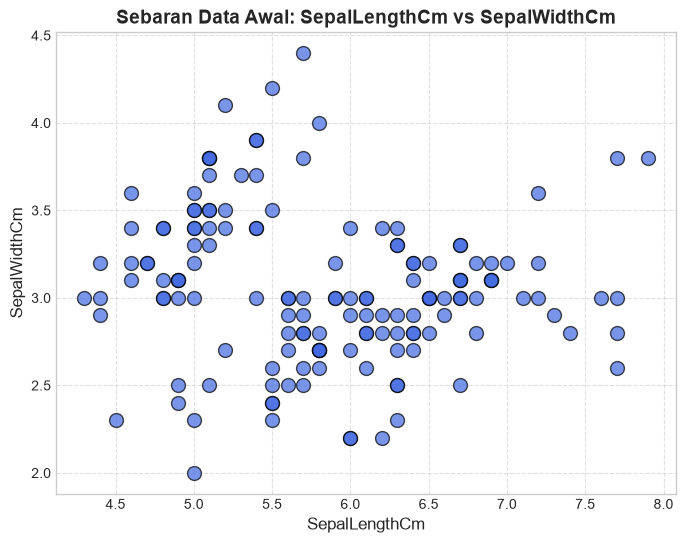

In [5]:
# Scatter plot awal SepalLengthCm vs SepalWidthCm
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, color='royalblue', edgecolors='k', alpha=0.7)
plt.title('Sebaran Data Awal: SepalLengthCm vs SepalWidthCm', fontsize=14, fontweight='bold')
plt.xlabel('SepalLengthCm', fontsize=12)
plt.ylabel('SepalWidthCm', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


Berdasarkan amatan visual dua dimensi di atas, terlihat ada 2 kelompok pemisahan besar: satu kelompok terisolasi di sisi kiri atas, dan kelompok lainnya lebih tersebar di sisi kanan tengah.


## Langkah 5 - Membuat Model K-Means (k = 2)
Sesuai hipotesis pengamatan visual, kita menginisiasi model K-Means dengan parameter `n_clusters=2`, melakukan fitting data, dan memplot hasil klasterisasi beserta titik pusat klaster (*centroids*).


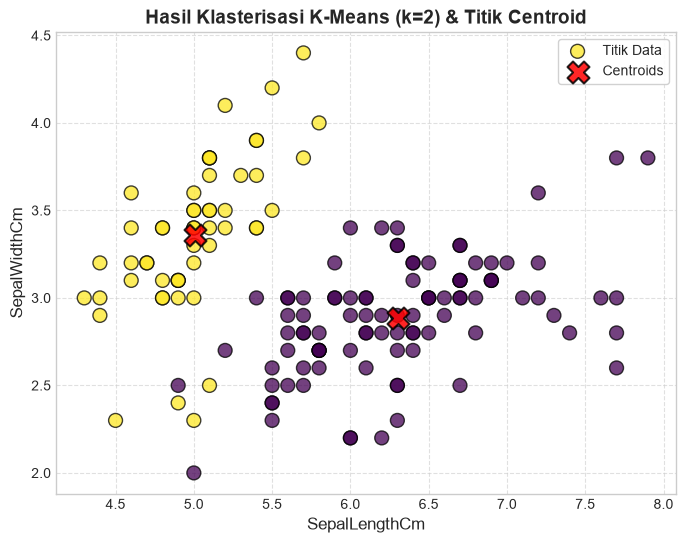

In [6]:
# Inisialisasi model K-Means dengan k=2
cl_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit dan prediksi label klaster
y_kmeans = cl_kmeans.fit_predict(X)

# Plotting hasil klasterisasi dan centroid
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans, cmap='viridis', edgecolors='k', alpha=0.75, label='Titik Data')

# Plot titik pusat klaster (Centroid)
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.85, marker='X', edgecolors='black', linewidth=1.5, label='Centroids')

plt.title('Hasil Klasterisasi K-Means (k=2) & Titik Centroid', fontsize=14, fontweight='bold')
plt.xlabel('SepalLengthCm', fontsize=12)
plt.ylabel('SepalWidthCm', fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## Langkah 6 - Evaluasi Model (Nilai SSE / Inertia)
Untuk mengevaluasi seberapa rapat titik-titik data terhadap titik pusat klasternya (*compactness*), kita memeriksa nilai **Sum of Squared Errors (SSE)** melalui properti `inertia_` dari objek K-Means.


In [7]:
# Tampilkan nilai SSE (Inertia)
print(f'Nilai SSE: {cl_kmeans.inertia_}')


Nilai SSE: 152.36870647733906


## Langkah 7 - Menentukan $k$ Terbaik dengan Elbow Method
Nilai SSE yang rendah belum tentu mencerminkan jumlah klaster yang optimal, karena nilai SSE akan selalu menurun mendekati nol seiring bertambahnya $k$. Oleh karena itu, kita menggunakan **Elbow Method** pada rentang $k = 1$ hingga $9$ untuk menemukan titik siku di mana laju penurunan SSE mulai melandai secara stabil.


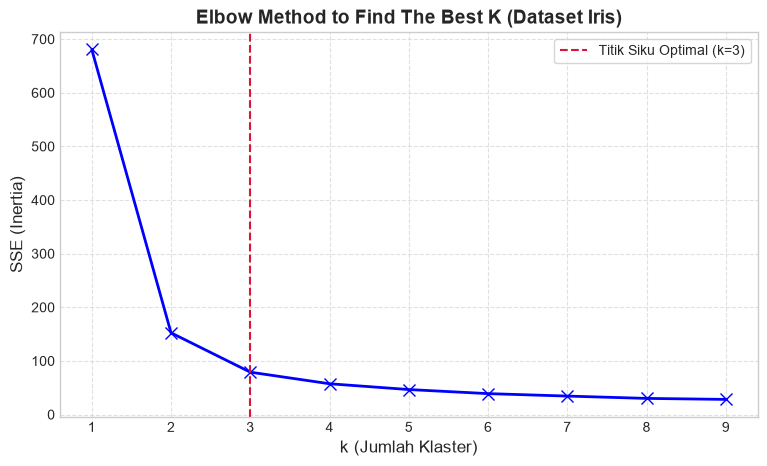

In [8]:
# Penentuan k terbaik dengan Elbow Method
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Visualisasi kurva distorsi SSE
plt.figure(figsize=(9, 5))
plt.plot(K, sse, 'bx-', linewidth=2, markersize=8)
plt.axvline(x=3, color='crimson', linestyle='--', linewidth=1.5, label='Titik Siku Optimal (k=3)')
plt.title('Elbow Method to Find The Best K (Dataset Iris)', fontsize=14, fontweight='bold')
plt.xlabel('k (Jumlah Klaster)', fontsize=12)
plt.ylabel('SSE (Inertia)', fontsize=12)
plt.xticks(list(K))
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Pembahasan & Kesimpulan Lab 1:
1. **Analisis Kurva Elbow**: Pada grafik di atas, penurunan SSE dari $k=1$ (680.82) ke $k=2$ (152.37) dan dari $k=2$ ke $k=3$ (78.95) sangat curam. Namun, mulai dari $k=3$ ke $k=4$ (57.44) hingga $k=9$ (28.76), laju penurunan SSE melandai secara konsisten.
2. **Justifikasi Nilai $k=3$**: Sudut siku (*elbow point*) terbentuk secara jelas pada **$k = 3$**. Hal ini selaras dengan struktur biologis asli dataset Iris yang memiliki 3 spesies (*Setosa*, *Versicolor*, dan *Virginica*).
